# Surface velocity of a river from a phone video

**37EFM Environmental Fluid Mechanics, TU/e**

A river carries foam, leaves and ripples on its surface. Filmed from a bridge, these move with the water, and tracking them between frames gives the surface velocity field. This is *large-scale particle image velocimetry* (LSPIV), the same technique as laboratory PIV but with the river providing the particles and a phone providing the camera.

The notebook goes from the raw movie to a map of the surface velocity in metres per second, in five steps:

1. **Read** the movie and its metadata.
2. **Stabilize** the frames: a hand-held phone moves, and that motion must not be mistaken for flow.
3. **Calibrate**: turn pixels into metres from two or more lengths that you measured in the field.
4. **PIV**: cross-correlate interrogation windows between frames to find displacements.
5. **Convert** the displacements to velocities and look at the result in plan view.

Each step is a short function in the package `rivpiv` that comes with this repository. Read the functions: they are written to be read, and the questions at the end ask about them.

The movie `data/IMG_0332.mov` is 3.7 s of the Dommel in Eindhoven, filmed from a footbridge on 6 November 2026.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import rivpiv
from rivpiv import video, stabilize, geometry, piv, plotting
from rivpiv.gui import ShapePicker, draw_shapes

DATA = Path('..') / 'data'
MOVIE = DATA / 'IMG_0332.mov'
SETUP_FILE = DATA / 'IMG_0332_setup.json'           # your own calibration (created below)
EXAMPLE_SETUP = DATA / 'IMG_0332_setup_example.json' # shipped placeholder, see its "notes"
plt.rcParams['figure.dpi'] = 80

## 1. The movie

`read_frames` returns the frames as grey levels (one byte per pixel) and a few numbers about the movie. The metadata written by the phone is read separately: it tells us the lens that was used, its focal length and where the movie was taken.

Full resolution is 1080 by 1920 pixels. The 111 frames take 230 MB in memory. If your computer struggles, pass `scale=0.5`; every pixel coordinate below then refers to the reduced frames, which the setup file records.

{'fps': 30.0, 'n_frames': 111, 'height': 1920, 'width': 1080, 'scale': 1.0, 'path': '../data/IMG_0332.mov'}
lens: iPhone 17 back dual wide camera 5.96mm f/1.6
35 mm-equivalent focal length: 26.0 mm
location (lat, lon, alt): (51.4458, 5.4831, 16.498)
recorded: 2026-11-06T12:25:18+01:00


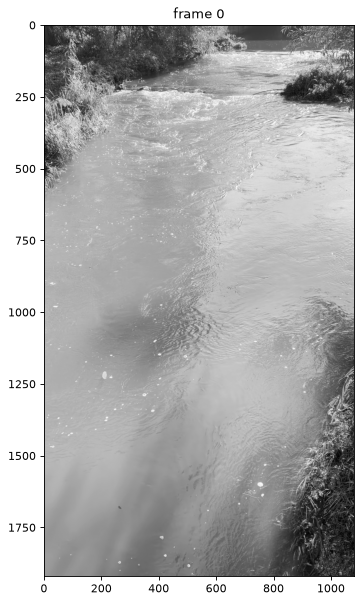

In [2]:
frames, info = video.read_frames(MOVIE, scale=1.0)
meta = video.read_metadata(MOVIE)
print(info)
print('lens:', meta['lens'])
print('35 mm-equivalent focal length:', meta['focal_length_35mm'], 'mm')
print('location (lat, lon, alt):', meta['location'])
print('recorded:', meta['creation_date'])

fig, ax = plt.subplots(figsize=(5, 9))
ax.imshow(frames[0], cmap='gray')
ax.set_title('frame 0');

The flow comes toward the camera: the rapids at the top are upstream. The left half of the river is covered with foam, which is ideal for PIV. The right half is smooth and reflects the trees and the sky. Keep that difference in mind when you judge the results.

## 2. Stabilizing the camera

The phone was held by hand. To see how much it moved, we track parts of the image that cannot move: the banks. Draw two or three rectangles on vegetation or ground, at different places in the image, with the tool below. Rectangles that include water, or the sky, are useless.

The tool needs an interactive backend. In JupyterLab, `%matplotlib widget` does that (package `ipympl`). Zoom and pan with the toolbar; clicks made while a toolbar tool is active are ignored. Press `u` to undo a point.

In [3]:
setup = geometry.Setup.load(SETUP_FILE if SETUP_FILE.exists() else EXAMPLE_SETUP)
setup.movie = MOVIE.name
setup.scale, setup.width, setup.height = info['scale'], info['width'], info['height']
print('loaded', SETUP_FILE if SETUP_FILE.exists() else EXAMPLE_SETUP)
print(setup.notes)

loaded ../data/IMG_0332_setup_example.json
EXAMPLE FILE. The segment lengths are placeholders computed from an assumed camera (5 m above the water, pitched 40 degrees down), not measurements. Replace them by measured lengths in the notebook and save your own IMG_0332_setup.json.


In [ ]:
%matplotlib widget
regions_picker = ShapePicker(frames[0], 'rectangle', initial=setup.static_regions,
                             title='Click two opposite corners of each rectangle on the banks')

In [5]:
%matplotlib inline
if regions_picker.result:
    setup.static_regions = regions_picker.result
print('static regions:', setup.static_regions)

static regions: [[0.0, 0.0, 240.0, 430.0], [880.0, 1320.0, 1080.0, 1900.0], [0.0, 0.0, 600.0, 100.0]]


For every frame, each rectangle is cross-correlated with the same rectangle in the first frame, which gives its shift to a fraction of a pixel. A translation of the phone shifts all rectangles equally; a roll of the phone shifts them differently. With two or more rectangles both are fitted, and every frame is mapped back onto the first.

residual shift of the static regions after stabilization: rms 1.0 px, largest 5.3 px


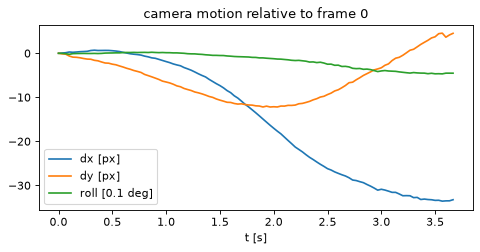

In [6]:
motion, region_shifts, quality = stabilize.estimate_motion(frames, setup.static_regions)
stab = stabilize.apply_motion(frames, motion)

fig, ax = plt.subplots(figsize=(7, 3))
t = np.arange(len(frames)) / info['fps']
ax.plot(t, motion[:, 0], label='dx [px]')
ax.plot(t, motion[:, 1], label='dy [px]')
ax.plot(t, np.degrees(motion[:, 2]) * 10, label='roll [0.1 deg]')
ax.set_xlabel('t [s]'); ax.legend(); ax.set_title('camera motion relative to frame 0');

# check: after stabilization the static regions should stay put to about a pixel.
# What remains is parallax: regions at different distances shift differently when the phone translates.
_, residual, _ = stabilize.estimate_motion(stab, setup.static_regions)
print('residual shift of the static regions after stabilization: '
      f'rms {np.sqrt(np.mean(residual ** 2)):.1f} px, largest {np.abs(residual).max():.1f} px')

Compare the size of the camera motion with the displacement of the water between frames, which you will find below. Without this step, what would the velocity field look like?

## 3. From pixels to metres

A photograph of a flat surface seen obliquely is a *perspective* image: one pixel covers more water far from the camera than close to it. To undo this we need the geometry of the camera: its height $h$ above the water, the angle $\theta$ by which it looks down, and the focal length $f$ (in pixels). The phone gives $f$ through its metadata. The two other numbers come from lengths that you measured in the field.

With $\xi = x - c_x$ and $\eta = y - c_y$ the pixel coordinates relative to the image centre, a point of the water surface at pixel $(x, y)$ lies at

$$X = \frac{h\,\xi}{D}, \qquad Y = \frac{h\,(f\cos\theta - \eta\sin\theta)}{D}, \qquad D = \eta\cos\theta + f\sin\theta,$$

where $X$ is measured to the right and $Y$ away from the camera, both in metres along the water surface. $D = 0$ is the horizon. The cross-stream scale $\partial X/\partial x = h/D$ is a metre-per-pixel factor whose inverse varies linearly with the row $y$. Two known lengths at two different rows therefore fix $h$ and $\theta$. A third known length makes the fit overdetermined and checks it; with three, the focal length can be fitted as well.

Draw each measured segment on the first frame, with both ends **on the water surface** (waterline to waterline, or between two floating marks), and type its length in metres. A point on top of the bank is above the water and would bias the result.

In [ ]:
%matplotlib widget
seg_picker = ShapePicker(frames[0], 'segment', initial=setup.segments)

In [8]:
%matplotlib inline
if seg_picker.result:
    setup.segments = seg_picker.result
setup.focal_length_px = video.focal_length_pixels(meta['focal_length_35mm'], info['width'], info['height'])
print('focal length:', round(setup.focal_length_px), 'px')
for s in setup.segments:
    print(f'segment ({s[0]:.0f}, {s[1]:.0f}) - ({s[2]:.0f}, {s[3]:.0f}): {s[4]} m')

focal length: 1387 px
segment (240, 230) - (830, 230): 8.88 m
segment (230, 250) - (30, 560): 10.58 m
segment (1000, 1300) - (1080, 1700): 1.66 m


In [9]:
cam, report = setup.fit(fit_focal=False)   # fit_focal=True needs three or more segments
print(cam)
for L, Lf, r in zip(report['measured_m'], report['fitted_m'], report['residual_percent']):
    print(f'  measured {L:6.2f} m   fitted {Lf:6.2f} m   ({r:+.1f} %)')
print(f'rms residual: {report["rms_percent"]:.1f} %')

CameraModel(h=5.01 m, theta=40.0 deg, f=1387 px, horizon row=-204)
  measured   8.88 m   fitted   8.89 m   (+0.1 %)
  measured  10.58 m   fitted  10.58 m   (-0.0 %)
  measured   1.66 m   fitted   1.66 m   (-0.0 %)
rms residual: 0.0 %


A plan view (an *orthophoto*) shows whether the calibration makes sense: in it, the river should have a constant width where it is straight, and the banks should run parallel.

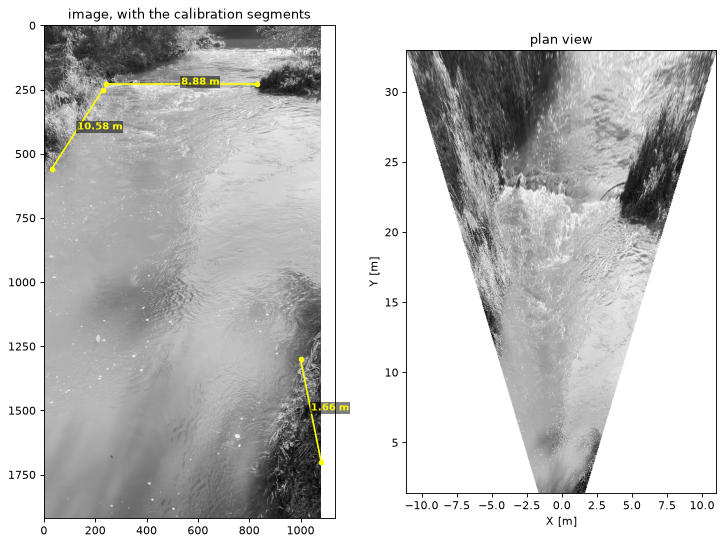

In [10]:
plan, extent = geometry.rectify(cam, stab[0], resolution=0.05)
fig, axs = plt.subplots(1, 2, figsize=(11, 8))
axs[0].imshow(stab[0], cmap='gray')
draw_shapes(axs[0], setup.segments, 'segment')
axs[0].set_title('image, with the calibration segments')
axs[1].imshow(plan, cmap='gray', extent=extent, origin='upper')
axs[1].set_xlabel('X [m]'); axs[1].set_ylabel('Y [m]'); axs[1].set_title('plan view');

Finally, outline the water with a polygon. Vectors found outside it, on the banks, are discarded.

In [ ]:
%matplotlib widget
water_picker = ShapePicker(frames[0], 'polygon', initial=[setup.water_polygon] if setup.water_polygon else None)

In [ ]:
%matplotlib inline
if water_picker.result:
    setup.water_polygon = [list(p) for p in np.array(water_picker.result[-1]).reshape(-1, 2)]
setup.notes = 'calibration by <your names>, lengths measured on <date>'
setup.save(SETUP_FILE)
print('saved', SETUP_FILE)

## 4. PIV

The idea is simple. Cut frame $i$ into square *interrogation windows* of, say, 64 pixels. For each window, slide it over frame $i + \Delta t$ and find the displacement $(d_x, d_y)$ for which the two match best. The match is measured by the cross-correlation

$$C(d_x, d_y) = \sum_{\text{window}} A(x, y)\, B(x + d_x, y + d_y),$$

computed quickly with the fast Fourier transform. The position of the peak of $C$ is the displacement of the water in that window.

Before correlating, each frame is high-pass filtered: the reflections of trees and sky, and the gradient of illumination across the river, vary slowly in space and do not move with the water. Left in, they would pull every vector toward zero.

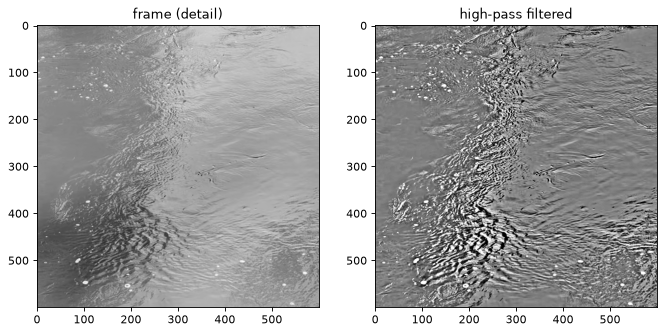

In [13]:
prep = dict(highpass_sigma=8)       # pixels; try 4 and 16 and look at the result
fig, axs = plt.subplots(1, 2, figsize=(10, 8))
axs[0].imshow(stab[0][600:1200, 300:900], cmap='gray'); axs[0].set_title('frame (detail)')
axs[1].imshow(piv.preprocess(stab[0], **prep)[600:1200, 300:900], cmap='gray', vmin=-30, vmax=30)
axs[1].set_title('high-pass filtered');

A river gives far fewer tracers than a seeded laboratory flow, and a single pair of frames often has no clear peak. The remedy is to **average the correlation maps of all pairs** before looking for the peak (*ensemble correlation*). This gives the mean flow over the clip, which is what we want here.

Two choices matter:

- `dt_frames`, the separation of the two frames of a pair. A larger separation gives a larger displacement, hence a more precise velocity, until the displacement approaches a quarter of the window and the peak is lost. The foreground moves fastest in pixels.
- `window`, the window size. Smaller windows resolve finer structure but contain fewer tracers.

In [14]:
fld = piv.ensemble_piv(stab, info['fps'], dt_frames=2, window=64, overlap=0.5, max_shift=20, prep=prep)
print('median displacement:', round(float(np.nanmedian(np.hypot(fld.u, fld.v))), 2), 'px per pair')

ensemble PIV: 109 pairs, 59x32 windows of 64 px, 50 s
median displacement: 2.84 px per pair


Not every window gives a believable vector. Three tests flag the bad ones:

1. **signal-to-noise ratio**: the main correlation peak must stand clearly above the second-highest peak;
2. **normalized median test** (Westerweel & Scarano 2005): a vector that differs from the median of its eight neighbours by more than a threshold, measured in units of the neighbours' own scatter, is an outlier;
3. the window must lie on the water.

1339 valid vectors out of 1599 on the water


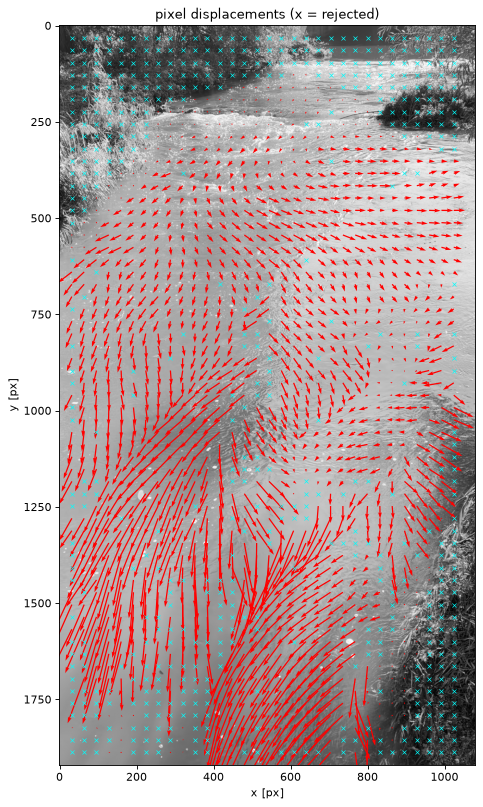

In [15]:
piv.validate(fld, snr_min=1.3, median_threshold=2.0, mask=setup.water_polygon)
n_water = piv.polygon_mask(setup.water_polygon, fld.x, fld.y).sum()
print(f'{fld.valid.sum()} valid vectors out of {n_water} on the water')

fig, ax = plt.subplots(figsize=(7, 12))
plotting.show_field_on_image(fld, stab[0], ax=ax, show_invalid=True, scale=0.1)
ax.set_title('pixel displacements (x = rejected)');

What happens inside one window is worth a look. The ensemble correlation map below is a function of the trial displacement; its peak is the displacement found. Try a window in the foam and one on the smooth water.

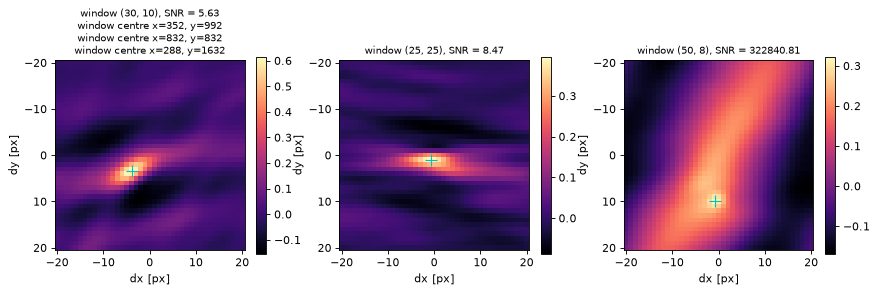

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, (j, i) in zip(axs, [(30, 10), (25, 25), (50, 8)]):
    plotting.show_correlation_map(fld, j, i, ax=ax)
    axs[0].set_title(axs[0].get_title() + f'\nwindow centre x={fld.x[j, i]:.0f}, y={fld.y[j, i]:.0f}', fontsize=9)

## 5. Velocities in metres per second

Each displacement is a step from one pixel to another. Mapping both pixels onto the water surface with the calibration, and dividing by the time between the two frames, gives the velocity in metres per second. The plan view shows the result as it would be seen from above.

surface speed: median 0.47 m/s, 90th percentile 0.66 m/s


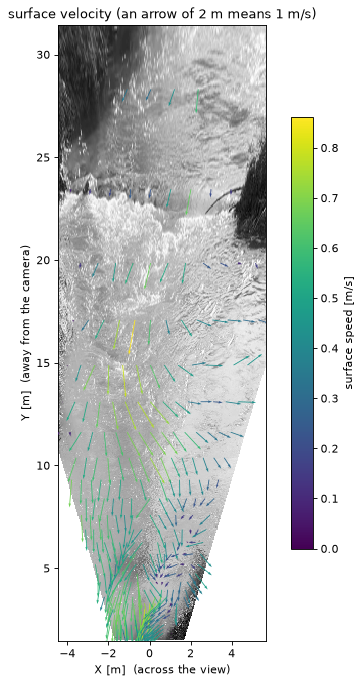

In [17]:
X, Y, U, V = plotting.world_field(fld, cam)
speed = np.hypot(U, V)
print(f'surface speed: median {np.nanmedian(speed):.2f} m/s, 90th percentile {np.nanpercentile(speed, 90):.2f} m/s')

fig, ax = plt.subplots(figsize=(8, 10))
plotting.show_plan_view(fld, cam, image=stab[0], every=2, ax=ax, arrow_scale=0.5, dots=False)
ax.set_title('surface velocity (an arrow of 2 m means 1 m/s)');

### A cross-section

Choose a line across the river, in world coordinates, and read the surface velocity along it. The component of the velocity normal to the line is what a discharge estimate needs. Interpolate the valid vectors onto the line with `griddata`.

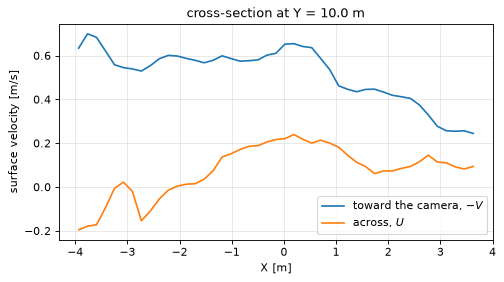

In [18]:
from scipy.interpolate import griddata

ok = np.isfinite(U) & np.isfinite(V)
pts = np.column_stack([X[ok], Y[ok]])

Y_section = 10.0                                  # metres from the camera, change at will
Xs = np.linspace(np.nanmin(X[ok]), np.nanmax(X[ok]), 60)
Us = griddata(pts, U[ok], (Xs, np.full_like(Xs, Y_section)), method='linear')
Vs = griddata(pts, V[ok], (Xs, np.full_like(Xs, Y_section)), method='linear')

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(Xs, -Vs, label='toward the camera, $-V$')
ax.plot(Xs, Us, label='across, $U$')
ax.set_xlabel('X [m]'); ax.set_ylabel('surface velocity [m/s]')
ax.set_title(f'cross-section at Y = {Y_section} m'); ax.legend(); ax.grid(alpha=0.3);

### Discharge

The discharge through a section is $Q = \int u_{\perp}(X)\, d(X)\, dX$ with $u_\perp$ the depth-averaged velocity normal to the section and $d$ the local depth. PIV gives the *surface* velocity, which is larger than the depth average; in rivers the ratio of the two, the *velocity index*, is usually about 0.85. The depth profile must be measured or assumed.

The profile below is an assumption, to show the computation. Replace it with measurements.

In [19]:
velocity_index = 0.85
width_left, width_right = np.nanmin(Xs[np.isfinite(Vs)]), np.nanmax(Xs[np.isfinite(Vs)])
depth = 0.8 * (1 - ((Xs - (width_left + width_right) / 2) / ((width_right - width_left) / 2)) ** 2)   # parabolic, 0.8 m deep, ASSUMED
depth = np.clip(depth, 0, None)
u_perp = np.where(np.isfinite(Vs), -Vs, 0.0)
Q = np.trapezoid(velocity_index * u_perp * depth, Xs)
print(f'discharge estimate: {Q:.2f} m^3/s   (assumed depth profile, velocity index {velocity_index})')

discharge estimate: 1.85 m^3/s   (assumed depth profile, velocity index 0.85)


## 6. Instantaneous fields

The ensemble correlation hides the time variation. Correlating single pairs gives one field per pair, noisier but time-resolved. From them, the mean and the fluctuations at a point follow.

instantaneous PIV: 37 pairs, 22 s


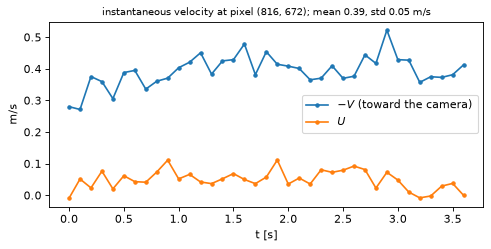

In [20]:
fields = piv.piv_sequence(stab, info['fps'], dt_frames=2, window=96, overlap=0.5, max_shift=24, prep=prep,
                          validate_kw=dict(snr_min=1.3, median_threshold=2.0, mask=setup.water_polygon), pair_step=3)
u_t = np.array([f.masked()[0] for f in fields])          # (n_pairs, ny, nx) displacements in px
v_t = np.array([f.masked()[1] for f in fields])
frac_valid = np.isfinite(u_t).mean(axis=0)

# a point in the foam: the grid node in the lower two thirds of the image with the most valid vectors
frac_valid[fields[0].y < info['height'] / 3] = 0
j, i = np.unravel_index(np.argmax(frac_valid), frac_valid.shape)
_, _, Ut, Vt = geometry.vectors_to_world(cam, fields[0].x[j, i], fields[0].y[j, i], u_t[:, j, i], v_t[:, j, i], fields[0].dt)
t_pairs = np.arange(0, len(stab) - 2, 3) / info['fps']
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(t_pairs, -Vt, '.-', label='$-V$ (toward the camera)')
ax.plot(t_pairs, Ut, '.-', label='$U$')
ax.set_xlabel('t [s]'); ax.set_ylabel('m/s'); ax.legend()
ax.set_title(f'instantaneous velocity at pixel ({fields[0].x[j, i]:.0f}, {fields[0].y[j, i]:.0f}); '
             f'mean {np.nanmean(-Vt):.2f}, std {np.nanstd(-Vt):.2f} m/s', fontsize=9);

## Questions

1. How large was the camera motion compared with the displacement of the water between two frames? What would a velocity field computed from the raw frames show?
2. The calibration gives a camera height and a pitch angle. Are they plausible for where you stood? Which of the two is more sensitive to an error in a measured length?
3. The focal length from the metadata is uncertain by about 10 %, because video modes crop the sensor. Change it by 10 % and refit. How much do the velocities change, and where in the image?
4. Why are vectors rejected on the smooth water on the right but accepted in the foam on the left? Look at the correlation maps of both.
5. Increase `dt_frames` until the foreground vectors fail. Explain the failure with the window size.
6. The correlation peak in the foam is elongated along the flow. What does that say about the precision of the velocity along the flow compared with across it?
7. How would you estimate the uncertainty of the discharge, given the uncertainties in calibration, surface velocity, velocity index and depth?

## References

- Adrian, R. J. and Westerweel, J., *Particle Image Velocimetry*, Cambridge University Press, 2011.
- Fujita, I., Muste, M. and Kruger, A., Large-scale particle image velocimetry for flow analysis in hydraulic engineering applications, *J. Hydraul. Res.* 36, 397-414, 1998.
- Meinhart, C. D., Wereley, S. T. and Santiago, J. G., A PIV algorithm for estimating time-averaged velocity fields, *J. Fluids Eng.* 122, 285-289, 2000.
- Westerweel, J. and Scarano, F., Universal outlier detection for PIV data, *Exp. Fluids* 39, 1096-1100, 2005.